<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Train: (12000, 32, 32, 3), Val: (3000, 32, 32, 3), Test: (3000, 32, 32, 3)



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 22s 66ms/step - accuracy: 0.2877 - loss: 1.9162 - val_accuracy: 0.4280 - val_loss: 1.6080
Epoch 2/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.4132 - loss: 1.6070 - val_accuracy: 0.4883 - val_loss: 1.3989
Epoch 3/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4709 - loss: 1.4561 - val_accuracy: 0.5157 - val_loss: 1.3314
Epoch 4/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5157 - loss: 1.3406 - val_accuracy: 0.5387 - val_loss: 1.2662
Epoch 5/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5529 - loss: 1.2556 - val_accuracy: 0.5800 - val_loss: 1.1871
Epoch 6/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5817 - loss: 1.1671 - val_accuracy: 0.5880 - val_loss: 1.1409
Epoch 7/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6092 - loss: 1.0991 - val_accuracy: 0.5917 - val_loss: 1.1305
Epoch 8/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6247 - loss: 1.0391 - val_accuracy: 

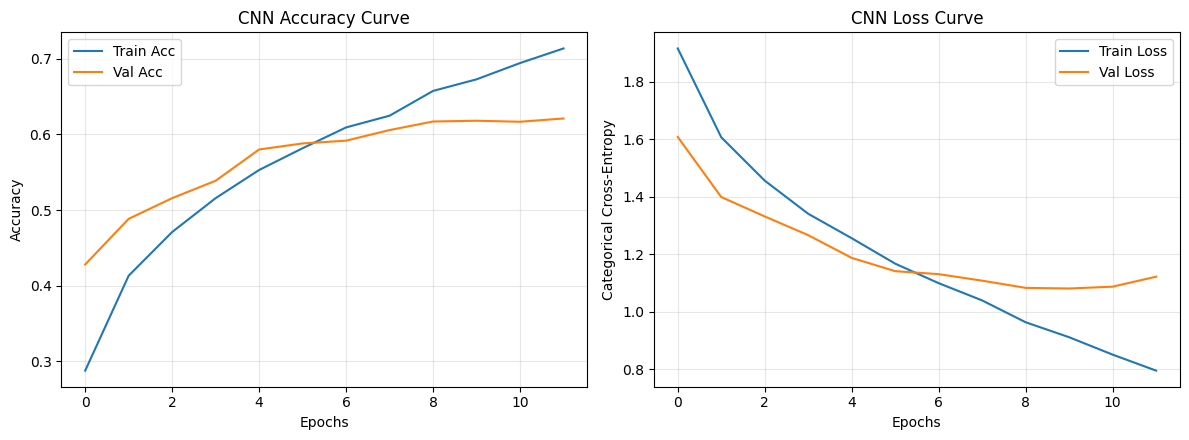

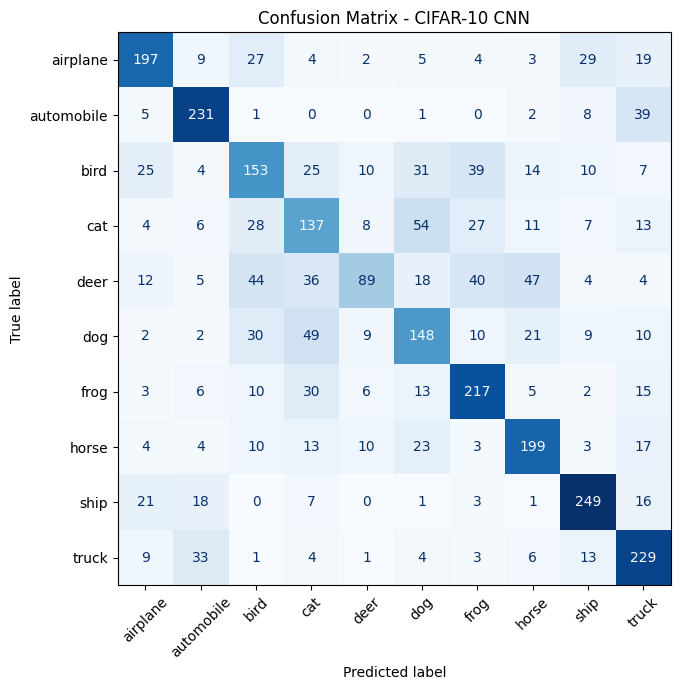

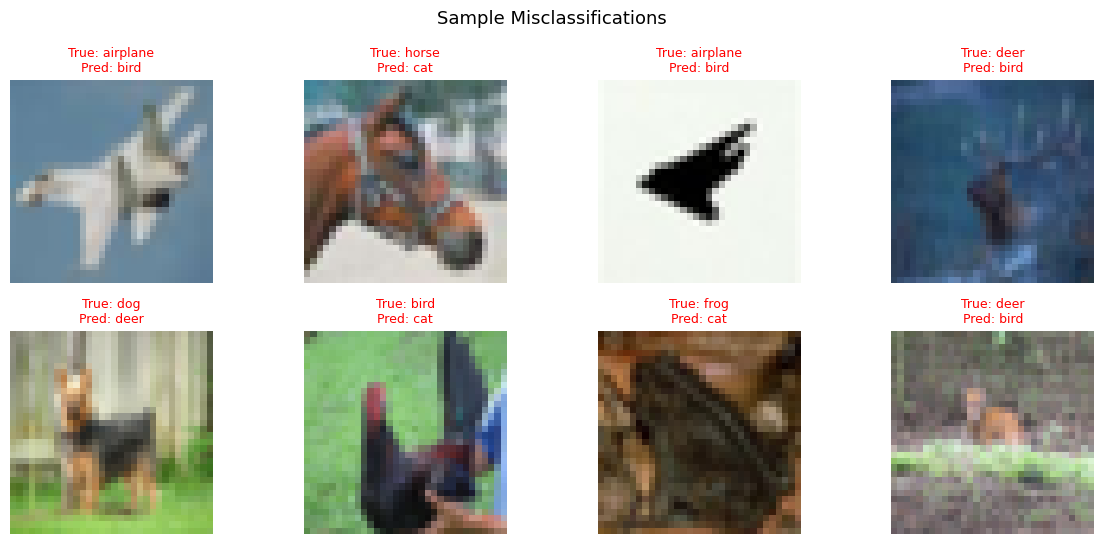

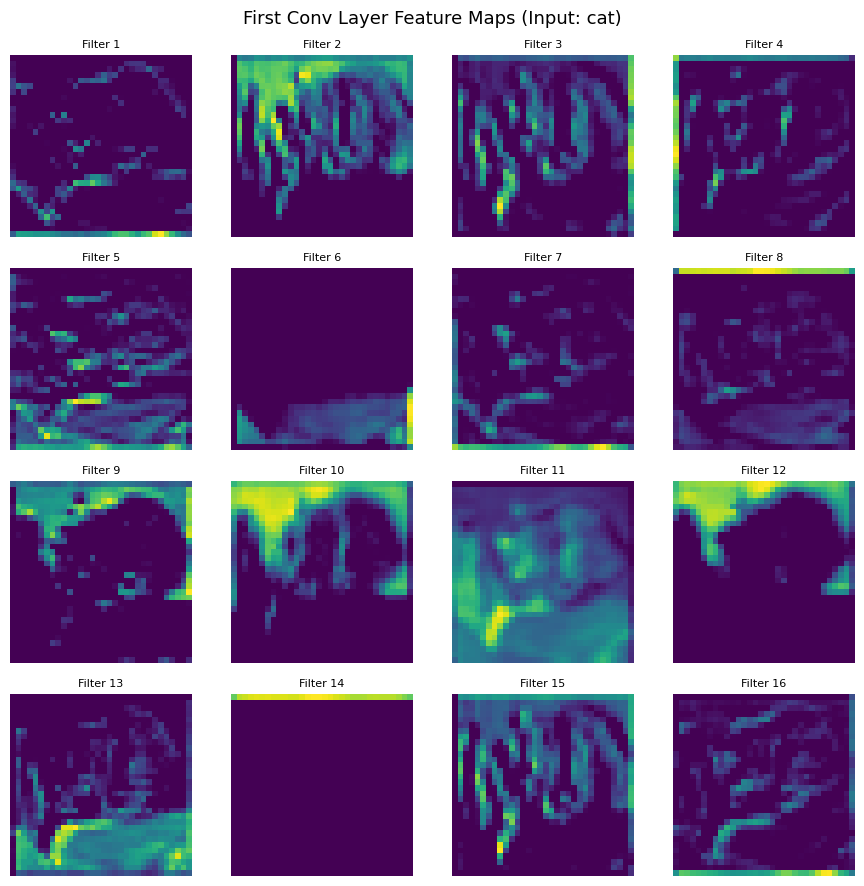

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Task 1: Load, Resize, Normalise & Split Dataset (CIFAR-10)
# ==========================================
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

(X_train_all, y_train_all), (X_test_all, y_test_all) = keras.datasets.cifar10.load_data()

# Use a balanced subset for fast execution on both CPU & GPU in Colab
X_train_sub, y_train_sub = X_train_all[:15000], y_train_all[:15000].ravel()
X_test, y_test = X_test_all[:3000], y_test_all[:3000].ravel()

# Resize (demonstrating explicit resize step to 32x32) and normalise to [0, 1]
IMG_SIZE = (32, 32)
X_train_sub = tf.image.resize(X_train_sub, IMG_SIZE).numpy() / 255.0
X_test = tf.image.resize(X_test, IMG_SIZE).numpy() / 255.0

# Split into Train and Validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_sub, y_train_sub, test_size=0.2, random_state=42, stratify=y_train_sub
)

# One-hot encode labels for categorical cross-entropy
num_classes = len(class_names)
y_train_cat = keras.utils.to_categorical(y_train, num_classes)
y_val_cat = keras.utils.to_categorical(y_val, num_classes)
y_test_cat = keras.utils.to_categorical(y_test, num_classes)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}\n")

# ==========================================
# Task 2: Build CNN (Conv, Pooling, Flatten, Dense)
# ==========================================
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1")(inputs)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv3")(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

# ==========================================
# Task 3: Train & Plot Accuracy and Loss Curves
# ==========================================
history = model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=12,
    batch_size=64,
    verbose=1
)

test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nTest Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history.history["accuracy"], label="Train Acc")
axes[0].plot(history.history["val_accuracy"], label="Val Acc")
axes[0].set_title("CNN Accuracy Curve")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Val Loss")
axes[1].set_title("CNN Loss Curve")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Categorical Cross-Entropy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 4: Confusion Matrix & Sample Misclassifications
# ==========================================
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix - CIFAR-10 CNN")
plt.tight_layout()
plt.show()

# Display 8 sample misclassifications
mis_idx = np.where(y_pred != y_test)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5))
for ax, idx in zip(axes.ravel(), mis_idx):
    ax.imshow(X_test[idx])
    ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9, color="red")
    ax.axis("off")
plt.suptitle("Sample Misclassifications", fontsize=13)
plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Visualise Feature Maps of First Conv Layer
# ==========================================
sample_img = X_test[0:1]
feature_map_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer("conv1").output
)
feature_maps = feature_map_model.predict(sample_img, verbose=0)[0]  # shape: (32, 32, 32)

# Plot original image + first 16 feature maps
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[:, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"First Conv Layer Feature Maps (Input: {class_names[y_test[0]]})", fontsize=13)
plt.tight_layout()
plt.show()